# CLAMATO: sparse absorption spectra to a complete cosmic flux volume


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `clamato_lyman_alpha_flux_volume` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：positions (1, 64332, 3) float64：Pixel positions, coordinate order x/y/z, in comoving Mpc/h；noise_std (1, 64332) float64：Released dimensionless flux-contrast noise standard deviations；flux_contrast (1, 64332) float64：Real dimensionless continuum-normalized absorption contrasts。恢复目标：完整三维Ly-alpha透射通量对比度场，无量纲。

获取模型：连续潜在场在稀疏sightline位置采样并叠加异方差噪声，先验为各向异性协方差。实际恢复算法：solvers.reconstruct：白化Wiener系统PCG，再乘map-data协方差。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:84原始Wiener方法提供baseline；没有独立宇宙场真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：clamato_lyman_alpha_flux_volume.ipynb单元3有保存图；图内容由该单元调用的本地visualization函数生成；clamato_lyman_alpha_flux_volume.ipynb单元7：5. Results: full-volume parity, noise ablation and display smoothing；clamato_lyman_alpha_flux_volume.ipynb单元8有保存图；图内容由该单元调用的本地visualization函数生成；clamato_lyman_alpha_flux_volume.ipynb单元10有保存图；图内容由该单元调用的本地visualization函数生成；clamato_lyman_alpha_flux_volume.ipynb单元12有保存图；图内容由该单元调用的本地visualization函数生成；clamato_lyman_alpha_flux_volume.ipynb单元14有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元3, 8, 10, 12, 14（从0计数）。代码单元7个，带execution_count的7个，保存PNG输出6幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem: a continuous three-dimensional absorption field

A background spectrum samples intervening neutral hydrogen along one narrow line. The real Keck-I/LRIS observations here constrain only sparse sightlines through a **30 × 24 × 438 Mpc/h** comoving volume. We reconstruct the dimensionless transmitted-flux fluctuation on **all 60 × 48 × 876 native cells**. This is an absorption-field reconstruction, not a direct mass-density or temperature measurement.

The independent original code result is a **method reference, not cosmic truth**. This notebook actively computes the full selected inverse and fresh comparisons using local mathematics. No preview/cache mode is used. Original upstream measurements, fresh local measurements and historical paper statements remain separate. See the provenance and gate evidence in `test/validation.md`.


In [1]:
%matplotlib inline
from pathlib import Path
import os, sys, json, time, platform, hashlib, importlib.util
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/physics_model.py').exists() and (p/'data/raw_data.npz').exists())
sys.path.insert(0, str(root))
from src.preprocessing import load_observations, grid_coordinates, Observations
from src.solvers import reconstruct
from src.main import run
from src import visualization as viz
spec = importlib.util.spec_from_file_location('standalone_review_judge', root/'evaluation/judge.py')
judge = importlib.util.module_from_spec(spec); spec.loader.exec_module(judge)
figure_dir = Path(os.environ.get('IMAGING_FIGURE_DIR', str(Path(os.environ.get('TEMP', '.'))/'imaging_clamato_review')))
reference_dir = root/'notebooks/reference_outputs'
environment = {'sys_executable':sys.executable,'python':platform.python_version(),'numpy':np.__version__,
               'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),
               'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}}
print(json.dumps(environment,indent=2))
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,
                     'axes.titlesize':11,'figure.facecolor':'white','savefig.facecolor':'white'})


{
  "sys_executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "python": "3.11.11",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "inline",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  }
}


## 2. Data: author-processed real spectra, preserved without clipping

The supplied **64,332** rows contain positions, observed contrast and released noise standard deviations. They are continuum-normalized spectral pixels, not raw CCD frames. The author noise floor of 0.2 is already present. Sightlines just outside a transverse grid edge still contribute to reconstruction and are retained.

Figure 1 shows measured positions, noise heterogeneity, the changing number of sightlines and the unmodified contrast distribution. Inverse contrast-noise is explicitly **not** the paper's continuum-to-noise ratio, which would require its continuum and mean-flux convention. Noise can give observed contrasts outside the noiseless flux range.


{'observation_count': 64332, 'native_voxel_count': 2522880, 'noise_range': [0.20000000298023224, 3.718513003887185]}


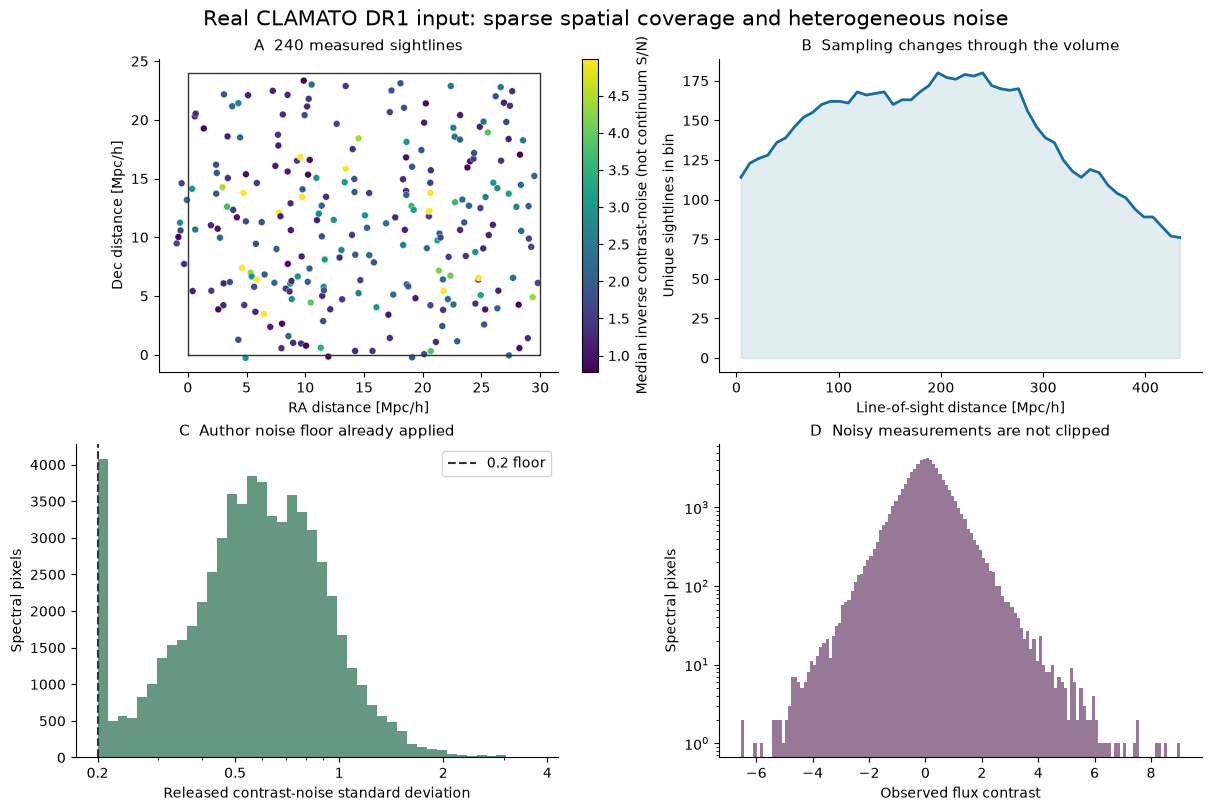

In [2]:
observations = load_observations(root/'data/raw_data.npz')
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False) as z:
    original = z['reconstruction'][0].copy()
with np.load(reference_dir/'original_diagnostics.npz',allow_pickle=False) as z:
    original_diagnostics = {k:z[k].copy() for k in z.files}
print({'observation_count':len(observations.flux),'native_voxel_count':original.size,
       'noise_range':[float(observations.noise.min()),float(observations.noise.max())]})
display(viz.figure01(observations,figure_dir)); plt.close('all')


## 3. Physics: the observation model and selected correlation discretization

Let $N=64332$ denote observation pixels and $M=60\times48\times876$ denote reconstructed grid cells. Position $\mathbf r_i$ has three comoving coordinates in Mpc/h, $d_i$ is observed contrast, $s$ is the unknown contrast field, and $\epsilon_i$ is measurement noise:

$$d_i=s(\mathbf r_i)+\epsilon_i,\qquad
\mathbb E[\epsilon_i\epsilon_j]=\sigma_i^2\delta_{ij},\qquad
d_i=\frac{f_i}{C_i\overline F_i}-1.$$

Here $f_i$ is observed spectral flux, $C_i$ is the estimated source continuum, $\overline F_i$ is the mean transmitted fraction and $\delta_{ij}$ is the Kronecker delta. The supplied data already implement the continuum operation. Negative contrast means stronger absorption.

The selected prior has zero mean and covariance

$$K(\mathbf a,\mathbf b)=v\,g(q),\qquad v=0.05,\qquad
q=\frac{(a_x-b_x)^2+(a_y-b_y)^2}{2L_\perp^2}
  +\frac{(a_z-b_z)^2}{2L_\parallel^2},$$

with $L_\perp=2.5$ Mpc/h and $L_\parallel=2.0$ Mpc/h. The source's $g$ linearly interpolates $\exp(-q)$ at **200 equally spaced samples over [0,8]**, and is zero for $q\geq8$. This lookup and finite cutoff are preserved, rather than silently replacing them by a different exact Gaussian. Generic spatial trees only find nonzero covariance pairs; the covariance mathematics is local.

The data are not enough to establish physical truth between sightlines. Continuum systematics, the assumed noise independence and the fixed correlation prior limit interpretation. In particular, the paper's reconstructed-map variance is not the same quantity as posterior covariance. The selected source configuration does not compute that expensive variance; the sensitivity plots below are not claimed to be calibrated uncertainty.


## 4. Method: an explicit whitened Wiener inverse

Write $K_{DD}$ for the $N\times N$ data covariance, $K_{GD}$ for the $M\times N$ grid-to-data covariance, $\mathbf d$ for measured contrasts and $N_c=\operatorname{diag}(\sigma_i^2)$ for the noise covariance. The conditional map is

$$\mathbf m=K_{GD}(K_{DD}+N_c)^{-1}\mathbf d.$$

With $W=\operatorname{diag}(1/\sigma_i)$, solve $A\mathbf y=\mathbf b$, where $A=I+WK_{DD}W$, $\mathbf b=W\mathbf d$, and $I$ is the identity matrix. Then coefficients $\boldsymbol\alpha=W\mathbf y$ give $\mathbf m=K_{GD}\boldsymbol\alpha$. The diagonal preconditioner is $P=\operatorname{diag}(1+v/\sigma_i^2)$.

The local implementation explicitly applies preconditioned conjugate gradients. Starting with $\mathbf y=0$, residual $\mathbf r=\mathbf b-A\mathbf y$, preconditioned residual $\mathbf z=P^{-1}\mathbf r$ and direction $\mathbf p=\mathbf z$, each update uses

$$\mathbf u=A\mathbf p,\quad
\eta=\frac{\mathbf r^\mathsf T\mathbf z}{\mathbf p^\mathsf T\mathbf u},\quad
\mathbf y\leftarrow\mathbf y+\eta\mathbf p,\quad
\mathbf r\leftarrow\mathbf r-\eta\mathbf u,$$

$$\mathbf z_{\rm new}=P^{-1}\mathbf r_{\rm new},\quad
\beta=\frac{\mathbf r_{\rm new}^\mathsf T\mathbf z_{\rm new}}{\mathbf r_{\rm old}^\mathsf T\mathbf z_{\rm old}},\quad
\mathbf p\leftarrow\mathbf z_{\rm new}+\beta\mathbf p.$$

The superscript $\mathsf T$ denotes transpose. Every 50th update recomputes $\mathbf r=\mathbf b-A\mathbf y$. Stop at $\|\mathbf r\|_2/\|\mathbf b\|_2\leq10^{-3}$, with at most 499 updates under the original loop convention. The native original run required 22 updates; a separate frozen step-3 refresh test covers the refresh branch while its residual is nonzero. No domain solver is imported.

The next cell performs the complete native inverse. It writes and evaluates a **fresh** submission and captures its actual timing. Reference tolerances were frozen from independent original repeats, measured float32 serialization and a more accurate original solve, before scoring the first full cleaned reconstruction.


In [3]:
start=time.perf_counter()
field,alpha,info=run(root)
fresh_seconds=time.perf_counter()-start
report,exit_code=judge.evaluate(root/'output/reconstruction.npz')
assert exit_code==0,report
(root/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
metrics=report['metrics']
diagnostic_parity={
    'coefficients_max_abs':float(np.max(np.abs(alpha-original_diagnostics['coefficients']))),
    'predicted_pixels_max_abs':float(np.max(np.abs(info['predicted_pixels']-original_diagnostics['predicted_pixels']))),
    'residual_history_max_abs':float(np.max(np.abs(info['residual_norms']-original_diagnostics['residual_norms'])))}
print(json.dumps({'fresh_active_seconds':fresh_seconds,'updates':info['iterations'],
                  'full_field_judge':report,'full_observation_diagnostic_parity':diagnostic_parity},indent=2))
np.savez_compressed(reference_dir/'fresh_measurements.npz',alpha=alpha,
                    predicted_pixels=info['predicted_pixels'],residual_norms=info['residual_norms'])


{
  "success": true,
  "iterations": 22,
  "covariance_seconds": 6.873836700004176,
  "covariance_nnz": 36353878,
  "relative_system_residual": 0.0007388573103226919,
  "runtime_seconds": 234.3455152999959
}


{
  "fresh_active_seconds": 235.20280880000792,
  "updates": 22,
  "full_field_judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "ncc_vs_ref": 1.0,
      "nrmse_vs_ref": 2.3209289832828493e-16
    },
    "thresholds": {
      "ncc_vs_ref": {
        "comparison": ">=",
        "boundary": 0.9999983011300956
      },
      "nrmse_vs_ref": {
        "comparison": "<=",
        "boundary": 0.00021655781007346957
      }
    },
    "errors": []
  },
  "full_observation_diagnostic_parity": {
    "coefficients_max_abs": 3.934630399271555e-13,
    "predicted_pixels_max_abs": 4.9404924595819466e-15,
    "residual_history_max_abs": 6.224354365258478e-12
  }
}


## 5. Results: full-volume parity, noise ablation and display smoothing

Figure 2 shows six native transverse sections spanning the complete volume. The shared display limits are $\pm0.6$ contrast, with colorbar extensions marking saturation; all voxel values are retained in evaluation. Red is stronger absorption. White denotes a value near zero, not missing or uncomputed data.

Figure 3 compares independently reproduced original and actively reconstructed local maps, using native longitudinal and transverse sections plus a subsampled display scatter. Its metrics use **every voxel**. Signed differences have symmetric color limits centered at zero. Longitudinal image panels stretch the display axes for readability; their distance labels remain physical. The original is a method reference, not truth.


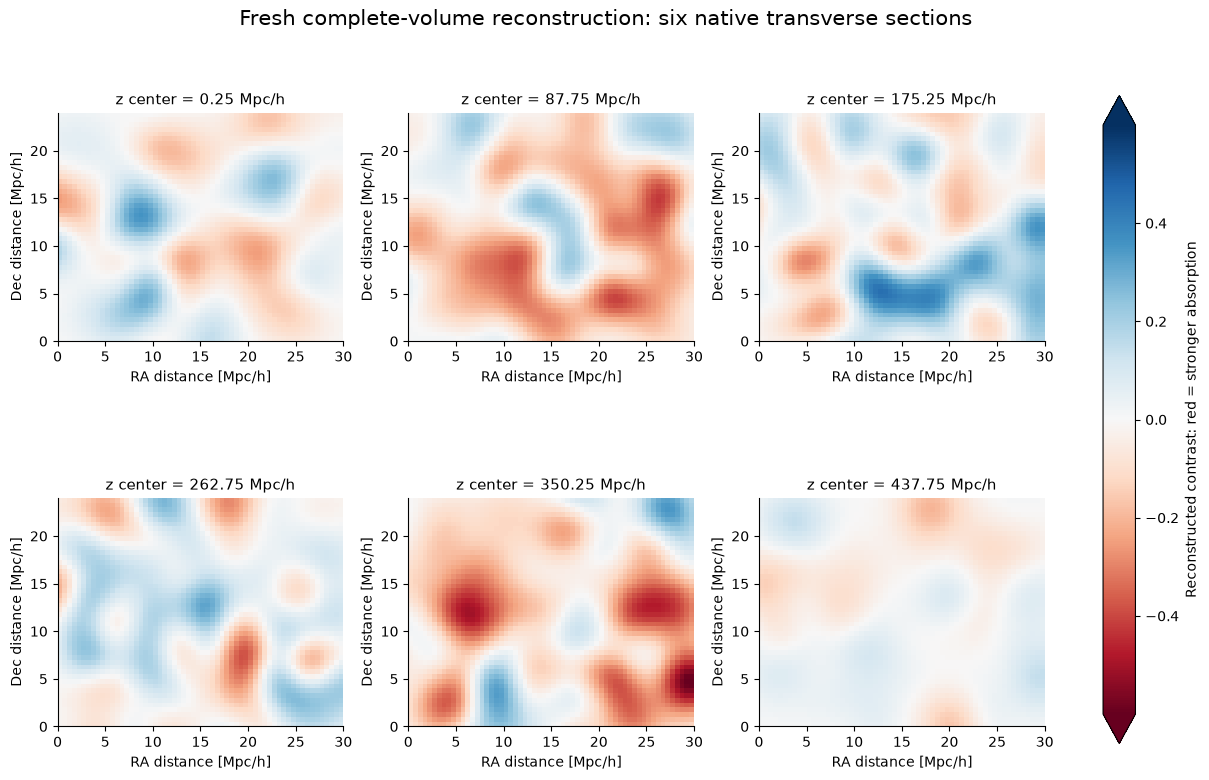

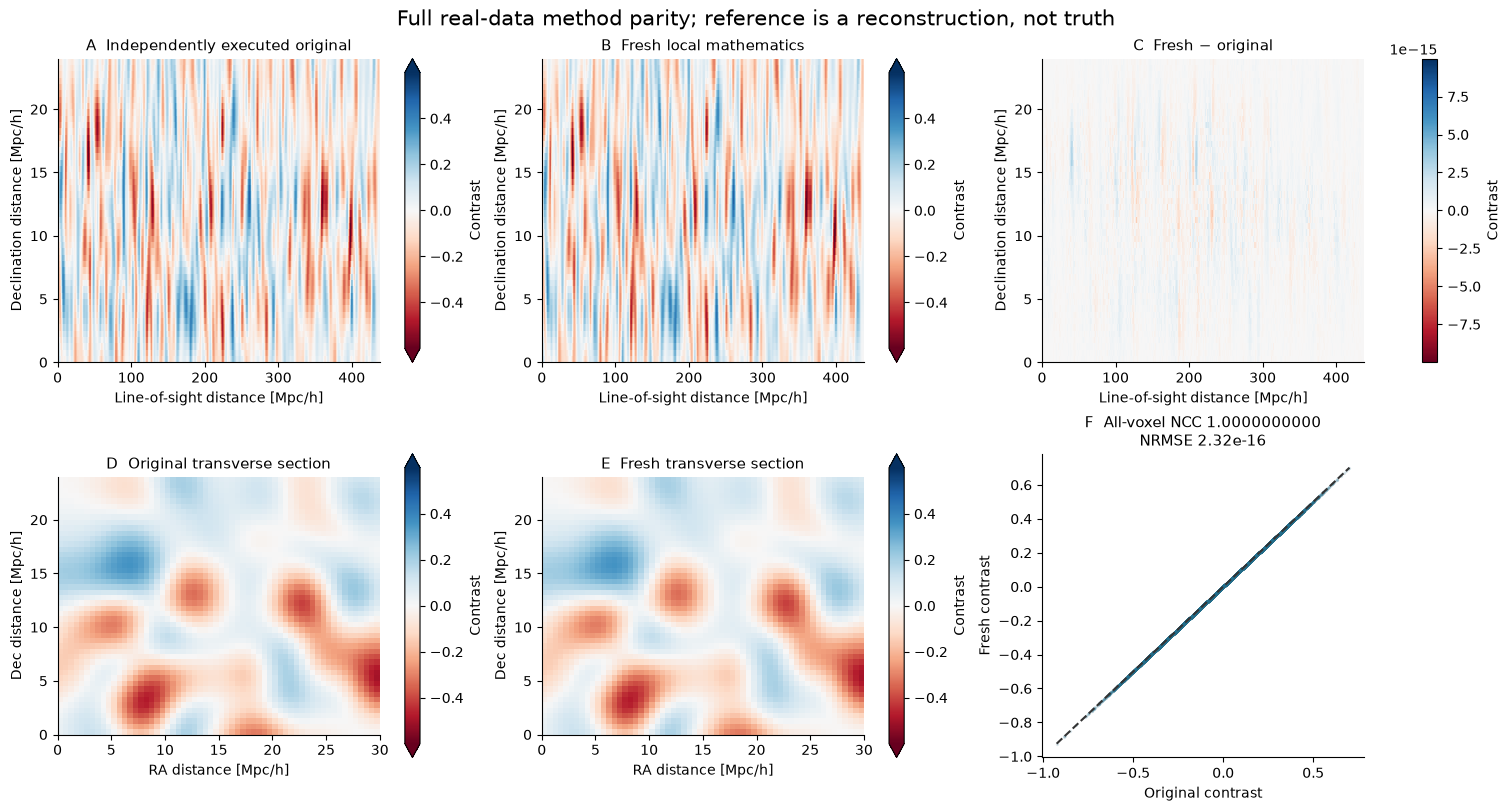

In [4]:
display(viz.figure02(field,figure_dir));plt.close('all')
display(viz.figure03(field,original,metrics,figure_dir));plt.close('all')


The equal-noise ablation actively resolves the **same complete observation set** after replacing only its weighting assumption by the median released standard deviation. It maps the full native middle-x plane, which is enough for an explicitly labeled diagnostic comparison; the primary task above reconstructs and grades the complete volume. Data RMS uses the original released standard deviations for both methods. Four disjoint rank quartiles prevent ties at the author floor from double counting observations. Residual histograms are display zooms; all residuals are saved.


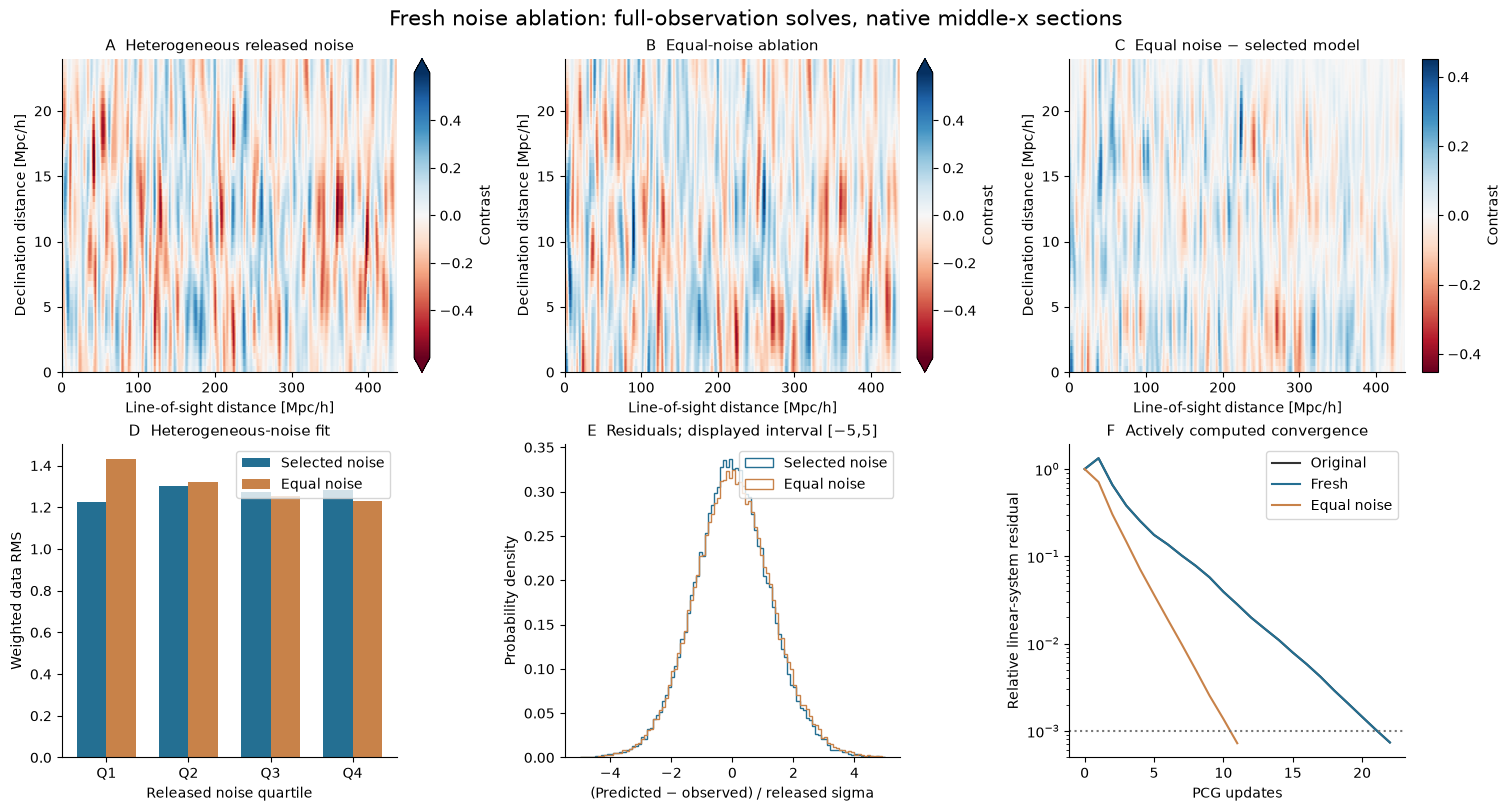

In [5]:
plane_coordinates=grid_coordinates().reshape(60,48,876,3)[30].reshape(-1,3)
equal_noise=Observations(observations.positions,np.full_like(observations.noise,np.median(observations.noise)),observations.flux)
uniform_plane,uniform_alpha,uniform_info=reconstruct(equal_noise,coordinates=plane_coordinates)
uniform_plane=uniform_plane.reshape(48,876)
display(viz.figure04(observations,field,info,uniform_plane,uniform_info,original_diagnostics['residual_norms'],figure_dir));plt.close('all')


Figure 5 computes extra Gaussian display smoothing at 1 and 2 Mpc/h on the fresh native map. The 2 Mpc/h scale follows the paper's visualization choice; this new diagnostic explicitly uses reflected boundaries rather than claiming unpublished original boundary details. It illustrates changes in structure profiles and longitudinal power. These smoothed maps are **not submitted**, and their differences from the native map measure a display operation, not error against physical truth.


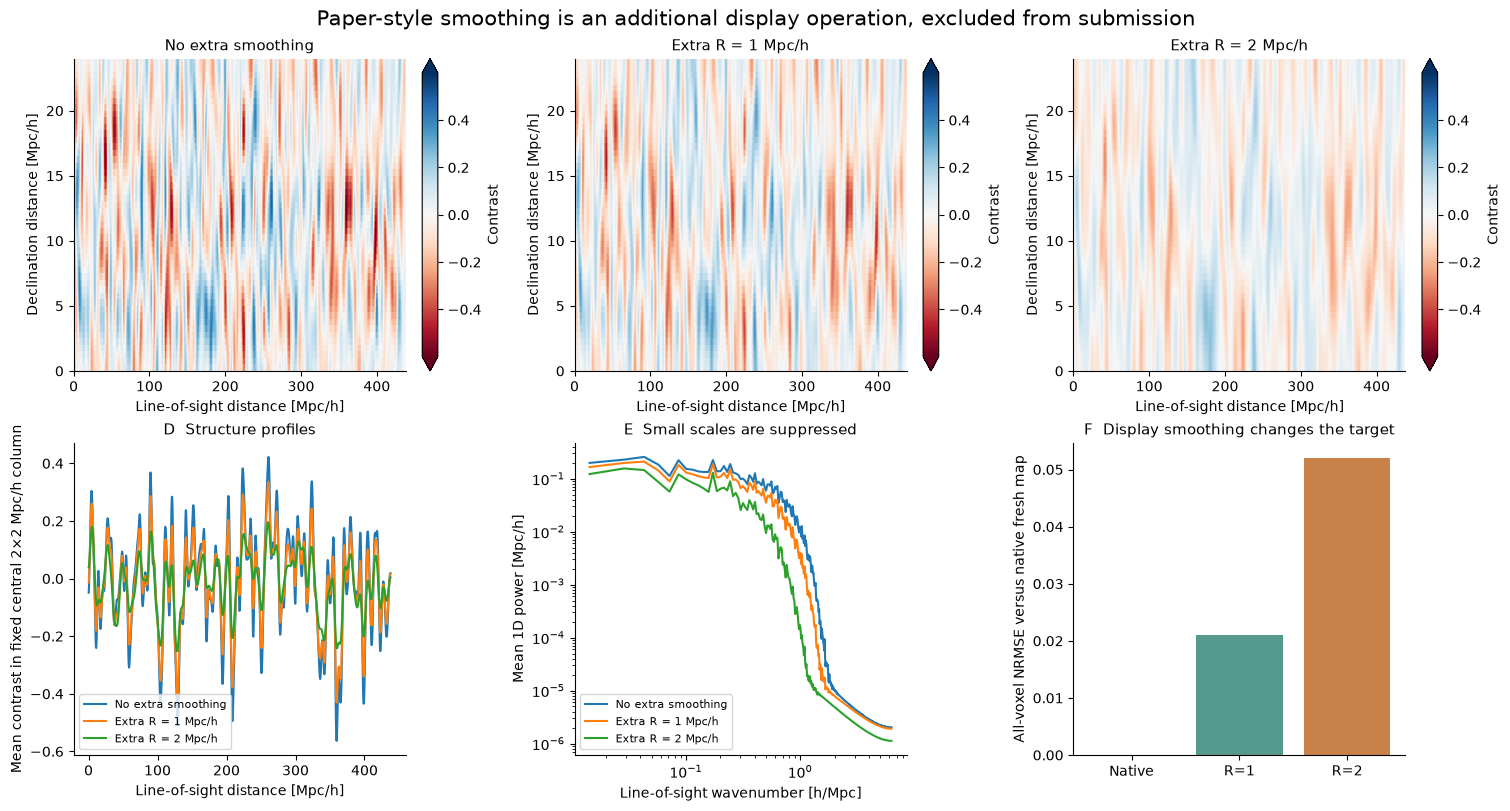

In [6]:
display(viz.figure05(field,figure_dir));plt.close('all')


## 6. Conclusion: what is reproducible and what remains conditional

Full-field original parity establishes the numerical extraction of this selected method. It does not independently validate the cosmic absorption field. To expose dependence on the correlation prior, Figure 6 actively solves all 64,332 unchanged observations with four alternative length choices, then maps the entire native middle-x plane. Differences use one common symmetric scale. The slice NRMSE and all-observation weighted data RMS are distinct quantities, labeled on separate axes. This is **model sensitivity**, not a calibrated uncertainty interval.


perp 2.0 {"lengths_Mpc_over_h": [2.0, 2.0, 2.0], "slice_nrmse_vs_selected": 0.028555351340921575, "weighted_data_rms": 1.2536418306581503, "updates": 19, "system_residual": 0.000891363268451103, "runtime_seconds": 7.877721700002439}


perp 3.0 {"lengths_Mpc_over_h": [3.0, 3.0, 2.0], "slice_nrmse_vs_selected": 0.0243657732470259, "weighted_data_rms": 1.2851392032287559, "updates": 24, "system_residual": 0.0007953635138472886, "runtime_seconds": 16.513169099998777}


parallel 1.5 {"lengths_Mpc_over_h": [2.5, 2.5, 1.5], "slice_nrmse_vs_selected": 0.02117761322620972, "weighted_data_rms": 1.259719361703042, "updates": 19, "system_residual": 0.0007151217087214508, "runtime_seconds": 8.95489729999099}


parallel 2.5 {"lengths_Mpc_over_h": [2.5, 2.5, 2.5], "slice_nrmse_vs_selected": 0.017898120719165585, "weighted_data_rms": 1.279883062125403, "updates": 24, "system_residual": 0.0008808498383625432, "runtime_seconds": 15.083281200000783}


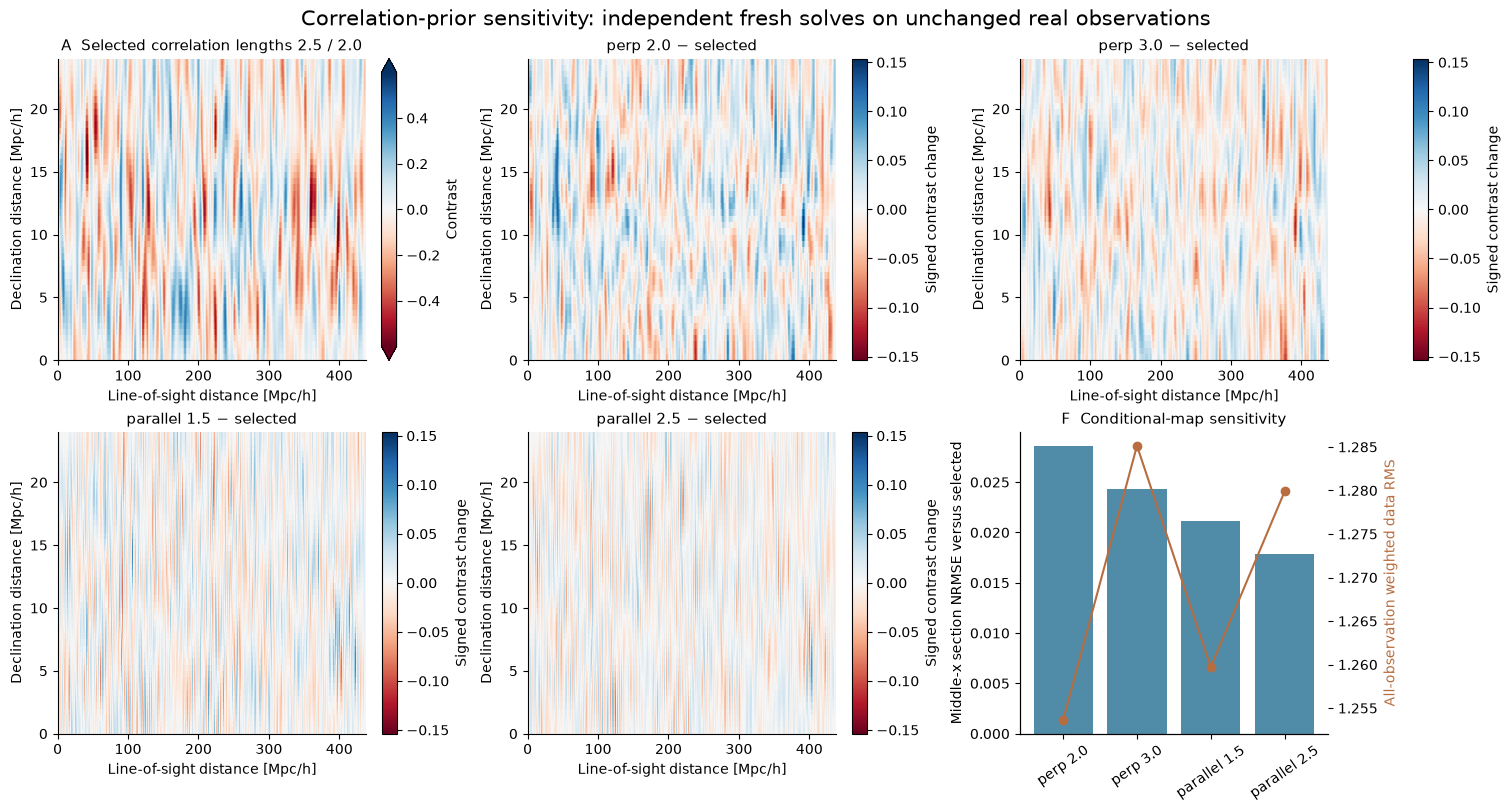

{
  "environment": {
    "sys_executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
    "python": "3.11.11",
    "numpy": "2.4.6",
    "scipy": "1.17.1",
    "matplotlib": "3.11.1",
    "backend": "inline",
    "threads": {
      "OMP_NUM_THREADS": "1",
      "OPENBLAS_NUM_THREADS": "1",
      "MKL_NUM_THREADS": "1"
    }
  },
  "fresh_active_seconds": 235.20280880000792,
  "full_field_metrics": {
    "ncc_vs_ref": 1.0,
    "nrmse_vs_ref": 2.3209289832828493e-16
  },
  "diagnostic_parity": {
    "coefficients_max_abs": 3.934630399271555e-13,
    "predicted_pixels_max_abs": 4.9404924595819466e-15,
    "residual_history_max_abs": 6.224354365258478e-12
  },
  "sensitivity": {
    "perp 2.0": {
      "lengths_Mpc_over_h": [
        2.0,
        2.0,
        2.0
      ],
      "slice_nrmse_vs_selected": 0.028555351340921575,
      "weighted_data_rms": 1.2536418306581503,
      "updates": 19,
      "system_residual": 0.000891363268451103,
 

In [7]:
variants=[('perp 2.0',(2.,2.,2.)),('perp 3.0',(3.,3.,2.)),
          ('parallel 1.5',(2.5,2.5,1.5)),('parallel 2.5',(2.5,2.5,2.5))]
sensitivity_slices={};sensitivity_metrics={}
for label,lengths in variants:
    a,_,details=reconstruct(observations,lengths=lengths,coordinates=plane_coordinates)
    a=a.reshape(48,876);sensitivity_slices[label]=a
    sensitivity_metrics[label]={'lengths_Mpc_over_h':list(lengths),
       'slice_nrmse_vs_selected':float(np.sqrt(np.mean((a-field[30])**2))/np.ptp(field[30])),
       'weighted_data_rms':float(np.sqrt(np.mean(((details['predicted_pixels']-observations.flux)/observations.noise)**2))),
       'updates':int(details['iterations']),'system_residual':float(details['relative_system_residual']),
       'runtime_seconds':float(details['runtime_seconds'])}
    print(label,json.dumps(sensitivity_metrics[label]),flush=True)
display(viz.figure06(field,sensitivity_slices,sensitivity_metrics,figure_dir));plt.close('all')
summary={'environment':environment,'fresh_active_seconds':fresh_seconds,'full_field_metrics':metrics,
         'diagnostic_parity':diagnostic_parity,'sensitivity':sensitivity_metrics,
         'data_sha256':hashlib.sha256((root/'data/raw_data.npz').read_bytes()).hexdigest(),
         'status':'Fresh complete-volume reconstruction passed independent Judge; comparisons are computed, reference is not truth.'}
(reference_dir/'fresh_measurements.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(summary,indent=2))


The recovered object is a complete three-dimensional transmitted-flux contrast volume conditional on the specified noise and correlation model. Its fine voxel spacing is not independent spatial resolution. The strong local/original numerical agreement, poor-control rejection and independent operator checks support reproducibility. They cannot remove continuum systematics, limited sightline sampling or the prior dependence demonstrated above.

The paper also compares to simulated true fields and external galaxy redshifts. Those independently calibrated truth/galaxy datasets are not bundled here, so their historical conclusions are not relabeled as new measurements. The task-relevant real-data story retains full-volume maps, original reproduction, noise-weighting comparison, convergence, additional smoothing and spatial prior sensitivity. No missing group is replaced with zeros or an archived result labeled fresh.

**Sources:** Lee et al., ApJS (2018), doi:10.3847/1538-4365/aace58, arXiv:1710.02894v3; CLAMATO DR1 doi:10.5281/zenodo.1292459. Exact source/data licenses, stage captures, original commands, numerical definitions and all validation gates are indexed in `test/validation.md`.
